# Preload Cloudinary from a CSV

When using Cloudinary, the auto-upload feature pulls videos from the origin when a request arrives. This notebook reads video URLs from `Top Hits Videos.csv` and sends requests through the configured Akamai delivery path to trigger that preload, without calling the Akamai Reporting API.

*This `Top Hits Videos.csv` can be downloaded from the [Akamai Video Manager](https://control.akamai.com/apps/image-manager-dashboard/#/video) dashboard.* 

## Load video URLs from CSV

Place `Top Hits Videos.csv` beside this notebook. The first column of each row must contain a video URL or hostname/path; any additional columns are ignored.

In [ ]:
import csv
from pathlib import Path
from urllib.parse import urlsplit

csv_path = Path("Top Hits Videos.csv")
video_targets = []

if csv_path.is_file():
    with csv_path.open(newline="", encoding="utf-8-sig") as csv_file:
        for row in csv.reader(csv_file):
            if not row:
                continue

            # Some exports quote the entire record, so decode that row once more.
            if len(row) == 1 and ',"' in row[0]:
                row = next(csv.reader([row[0]]))

            raw_url = row[0].strip()
            if not raw_url:
                continue

            # The CSV contains hostname/path values without a URL scheme.
            parts = urlsplit(raw_url if "://" in raw_url else f"//{raw_url}")
            if parts.netloc and parts.path:
                video_targets.append({"hostname": parts.netloc, "path": parts.path})
else:
    print(f"{csv_path} not found. Place it beside the notebook before loading URLs.")

print(f"Loaded {len(video_targets)} hostname/path items from {csv_path}")
video_targets[:10]

## Preload videos through Cloudinary

The CSV loader builds hostname/path targets from the first column. The next cell requests each target through the customer delivery configuration, following the flow *request → Akamai → Cloudinary auto-upload → response*.

This test uses `MAX_ITEMS`. Increase it or remove the `[:MAX_ITEMS]` slice to process more entries.

> **Note:** This example uses Akamai Staging. The `curl` request uses `--resolve` with `STAGING_IP` to direct requests to the staging platform.

In [ ]:
import subprocess

STAGING_IP = "23.50.55.49"
MAX_ITEMS = 15

if not video_targets:
    print("No video targets found. Run the CSV loading cell first and ensure it returns items.")
    results = []
else:
    sample_targets = video_targets[:MAX_ITEMS]
    print(f"Running HEAD checks for {len(sample_targets)} targets via {STAGING_IP}...")

    results = []
    for i, target in enumerate(sample_targets, start=1):
        hostname = target["hostname"]
        path = target["path"]
        url = f"https://{hostname}{path}"

        # HEAD request with DNS override to Akamai staging.
        cmd = [
            "curl",
            "-I",
            "-s",
            "-D",
            "-",
            "-o",
            "/dev/null",
            "-w",
            "\n__HTTP_CODE__:%{http_code}",
            "--connect-timeout",
            "10",
            "--max-time",
            "20",
            url,
            "--resolve",
            f"{hostname}:443:{STAGING_IP}",
        ]

        proc = subprocess.run(cmd, capture_output=True, text=True)

        if proc.returncode == 0:
            output = proc.stdout
            content_type = ""
            status_code = "000"

            for line in output.splitlines():
                lower_line = line.lower()
                if lower_line.startswith("content-type:"):
                    content_type = line.split(":", 1)[1].strip()
                elif line.startswith("__HTTP_CODE__:"):
                    status_code = line.split(":", 1)[1].strip()
        else:
            status_code = f"CURL_ERROR_{proc.returncode}"
            content_type = ""

        results.append(
            {
                "hostname": hostname,
                "path": path,
                "status_code": status_code,
                "content_type": content_type,
            }
        )
        print(f"{i}/{len(sample_targets)} {hostname}{path} -> {status_code} {content_type}")

# results

## Check assets in Cloudinary

You should now see new videos in your Cloudinary assets with a little blue dot.
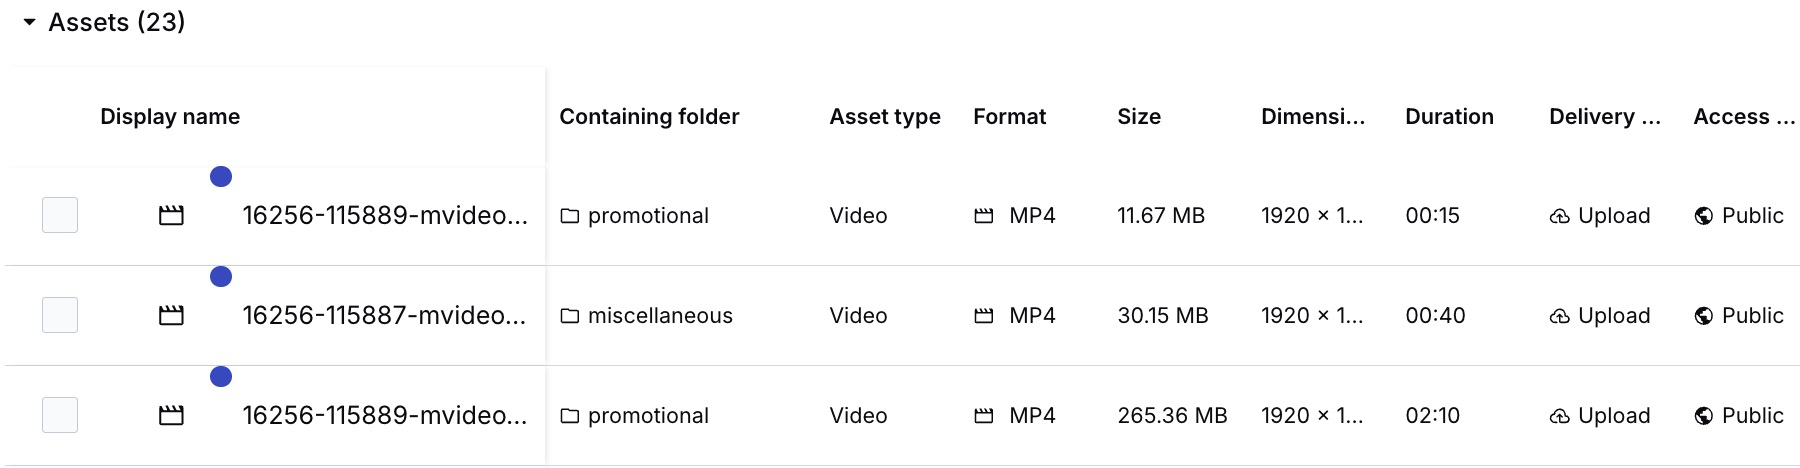